<a href="https://colab.research.google.com/github/sigma-asif/ml-core-intuition/blob/main/3.Scratch%20SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scratch SVM with Gradient Descent — Step-by-Step Notebook

এই notebook-এ দেওয়া SVM code-টিকে logical অংশ অনুযায়ী আলাদা cell-এ সাজানো হয়েছে। প্রতিটি ধাপের আগে Markdown note আছে, যাতে কোন অংশে কী হচ্ছে এবং কেন হচ্ছে তা বোঝা যায়।

**গুরুত্বপূর্ণ:** মূল training logic, dataset, hyperparameters, loss function এবং parameter-update equations পরিবর্তন করা হয়নি। কোডটি শুধু cell-wise সাজানো হয়েছে।

## Step 1 — Import Libraries

প্রথমে প্রয়োজনীয় Python library import করছি:

- `NumPy`: numerical calculation এবং array operation।
- `Pandas`: dataset-কে table আকারে দেখানোর জন্য।
- `Matplotlib`: dataset, cost, accuracy এবং decision boundary plot করার জন্য।

এই cell একবার run করলেই পরের cell-গুলোতে library ব্যবহার করা যাবে।

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 2 — Create the Dataset

এখানে মোট ১৬টি data point তৈরি করা হয়েছে।

- `X_neg`: Class `-1`-এর ৮টি point।
- `X_pos`: Class `+1`-এর ৮টি point।
- প্রতিটি point-এর দুটি feature আছে: `x1` এবং `x2`।
- `y`: প্রতিটি point-এর actual class label।

`np.vstack()` দিয়ে দুই class-এর feature একসঙ্গে এবং `np.concatenate()` দিয়ে label একসঙ্গে করা হয়েছে।

In [2]:
# ==========================================
# ১৬টি ডেটা পয়েন্ট তৈরি (x1, x2, y)
# y in {-1, +1}
# ==========================================
np.random.seed(42)

# Class -1 (8 points)
X_neg = np.array([
    [1.5, 22.0],
    [2.0, 28.0],
    [2.5, 34.0],
    [3.0, 26.0],
    [3.2, 38.0],
    [3.8, 31.0],
    [4.0, 42.0],
    [4.3, 35.0]
])
y_neg = -np.ones(len(X_neg))

# Class +1 (8 points)
X_pos = np.array([
    [5.8, 52.0],
    [6.2, 60.0],
    [6.5, 48.0],
    [7.0, 66.0],
    [7.4, 56.0],
    [7.8, 72.0],
    [8.3, 62.0],
    [8.8, 76.0]
])
y_pos = np.ones(len(X_pos))

X = np.vstack([X_neg, X_pos])
y = np.concatenate([y_neg, y_pos])

df = pd.DataFrame({
    "ID": [f"P{i+1}" for i in range(len(y))],
    "x1": X[:, 0],
    "x2": X[:, 1],
    "y": y.astype(int)
})

print("=== ১৬টি ডেটা পয়েন্টের টেবিল ===")
print(df.to_string(index=False))
print(f"\nTotal samples: {len(y)} | Class -1: {np.sum(y == -1)} | Class +1: {np.sum(y == 1)}")

=== ১৬টি ডেটা পয়েন্টের টেবিল ===
 ID  x1   x2  y
 P1 1.5 22.0 -1
 P2 2.0 28.0 -1
 P3 2.5 34.0 -1
 P4 3.0 26.0 -1
 P5 3.2 38.0 -1
 P6 3.8 31.0 -1
 P7 4.0 42.0 -1
 P8 4.3 35.0 -1
 P9 5.8 52.0  1
P10 6.2 60.0  1
P11 6.5 48.0  1
P12 7.0 66.0  1
P13 7.4 56.0  1
P14 7.8 72.0  1
P15 8.3 62.0  1
P16 8.8 76.0  1

Total samples: 16 | Class -1: 8 | Class +1: 8


## Step 3 — Visualise the Raw Dataset

Training শুরু করার আগে scatter plot-এ data point-গুলো দেখা হচ্ছে।

- Orange square = Class `-1`
- Blue circle = Class `+1`
- `P1` থেকে `P16` = প্রতিটি data point-এর ID

এই plot দেখে বোঝা যাবে দুই class-এর point-গুলো feature space-এ কোথায় অবস্থান করছে।

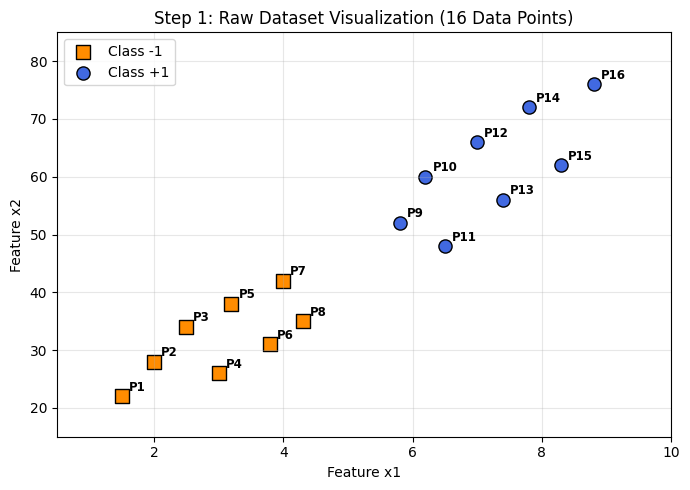

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(X[y == -1, 0], X[y == -1, 1], c="darkorange", marker="s", s=90, edgecolors="k", label="Class -1")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="royalblue", marker="o", s=90, edgecolors="k", label="Class +1")

for i in range(len(y)):
    plt.annotate(f"P{i+1}", (X[i, 0], X[i, 1]), textcoords="offset points", xytext=(5, 4), fontsize=8.5, fontweight="bold")

plt.title("Step 1: Raw Dataset Visualization (16 Data Points)")
plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.xlim(0.5, 10.0)
plt.ylim(15.0, 85.0)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 4 — Standardisation Helper Functions

The features `x1` and `x2` have different numerical scales. So, we standardise them before training to make the optimisation process more stable.

**Standardisation Formula:**

$$
x_{\text{scaled}} = \frac{x - \mu}{\sigma}
$$

Where:
- `x` = Original feature value.
- `μ` = Mean of the feature.
- `σ` = Standard deviation.

**Why the second function?**

The model learns `w` and `b` using standardised data. The second function converts these parameters back to the original scale so that we can calculate predictions and plot the decision boundary using the original dataset.

In [5]:
def standardize_fit_transform(X):
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    std_safe = np.where(std == 0, 1.0, std)
    return (X - mean) / std_safe, mean, std_safe

def convert_params_to_original_scale(w_scaled, b_scaled, mean, std):
    w_orig = w_scaled / std
    b_orig = b_scaled - np.sum(w_scaled * mean / std)
    return w_orig, b_orig

## Step 5 — Define the Scratch SVM Training Function

এটি notebook-এর মূল training function। এখানে SVM-এর objective/cost function ব্যবহার করা হয়েছে:

$$
J(w,b) = \frac{1}{2}\lVert w \rVert^2 + C\sum_{i=1}^{n}\max(0, 1 - y_i f(x_i))
$$

যেখানে:

- `w`: weight vector
- `b`: bias
- `f(x_i) = w^T x_i + b`: prediction score
- `y_i`: actual label (`-1` অথবা `+1`)
- `C`: hinge loss-এর penalty strength
- `max(0, 1 - y_i f(x_i))`: hinge loss

যে point-এর জন্য `y_i * f(x_i) < 1`, সেটি margin condition ভঙ্গ করছে বা margin-এর ভেতরে আছে। সেই point-গুলো ব্যবহার করে `dw` এবং `db` হিসাব করা হয়। এরপর learning rate দিয়ে `w` ও `b` update হয়।

`history`-তে প্রতিটি epoch-এর cost, accuracy এবং violating point-এর সংখ্যা রাখা হয়, যাতে পরে graph আঁকা যায়।

In [6]:
def train_svm_scratch(X_data, y_data, C=10.0, lr=0.005, epochs=4000, w_init=None, b_init=None):
    w = np.zeros(X_data.shape[1]) if w_init is None else w_init.astype(float).copy()
    b = 0.0 if b_init is None else float(b_init)

    history = {
        "epoch": [],
        "cost": [],
        "accuracy": [],
        "violating_count": []
    }

    for ep in range(epochs):
        scores = X_data @ w + b
        margins = y_data * scores
        hinge_loss = np.maximum(0.0, 1.0 - margins)

        cost = 0.5 * np.sum(w ** 2) + C * np.sum(hinge_loss)
        preds = np.where(scores >= 0.0, 1.0, -1.0)
        acc = np.mean(preds == y_data)

        # শর্ত ভঙ্গকারী পয়েন্ট: y_i * f(x_i) < 1
        viol = margins < 1.0

        if np.any(viol):
            dw = w - C * (X_data[viol].T @ y_data[viol])
            db = -C * np.sum(y_data[viol])
        else:
            dw = w.copy()
            db = 0.0

        w -= lr * dw
        b -= lr * db

        history["epoch"].append(ep)
        history["cost"].append(cost)
        history["accuracy"].append(acc * 100.0)
        history["violating_count"].append(np.sum(viol))

    return w, b, history

## Step 6 — Standardise Data and Test the Bad Initial Parameters

প্রথমে dataset standardise করা হচ্ছে।

এরপর ইচ্ছাকৃতভাবে একটি ভুল initial weight vector নেওয়া হয়েছে:

$$
w = [-1.5,\, -1.5],\qquad b = 0
$$

এই parameters original scale-এ convert করে প্রতিটি point-এর score ও prediction দেখা হচ্ছে। উদ্দেশ্য হলো training-এর আগের অবস্থাটি বোঝা এবং পরে training-এর ফলের সঙ্গে তুলনা করা।

In [7]:
X_scaled, mean_X, std_X = standardize_fit_transform(X)

w_bad_s = np.array([-1.5, -1.5])
b_bad_s = 0.0
w_bad_orig, b_bad_orig = convert_params_to_original_scale(w_bad_s, b_bad_s, mean_X, std_X)

bad_scores = X @ w_bad_orig + b_bad_orig
bad_preds = np.where(bad_scores >= 0, 1, -1)

print(f"\n=== শুরুর (ভুল) প্যারামিটারে Accuracy: {np.mean(bad_preds == y)*100:.1f}% ===")
for i in range(len(y)):
    print(f"P{i+1:02d} ({X[i,0]:3.1f}, {X[i,1]:4.1f}) | Actual={int(y[i]):+d} | Bad Pred={int(bad_preds[i]):+d} | y*f(x)={y[i]*bad_scores[i]:6.2f}")


=== শুরুর (ভুল) প্যারামিটারে Accuracy: 0.0% ===
P01 (1.5, 22.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -4.60
P02 (2.0, 28.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -3.73
P03 (2.5, 34.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -2.87
P04 (3.0, 26.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -3.26
P05 (3.2, 38.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -2.05
P06 (3.8, 31.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -2.29
P07 (4.0, 42.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -1.17
P08 (4.3, 35.0) | Actual=-1 | Bad Pred=+1 | y*f(x)= -1.60
P09 (5.8, 52.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -0.91
P10 (6.2, 60.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -1.89
P11 (6.5, 48.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -1.01
P12 (7.0, 66.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -2.95
P13 (7.4, 56.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -2.31
P14 (7.8, 72.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -4.02
P15 (8.3, 62.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -3.44
P16 (8.8, 76.0) | Actual=+1 | Bad Pred=-1 | y*f(x)= -5.03


## Step 7 — Train the SVM

এখন `C = 10.0`, learning rate `0.005` এবং `4000` epochs ব্যবহার করে training চালানো হচ্ছে।

Training শুরু হচ্ছে আগের ভুল initial parameters থেকে। Training শেষে পাওয়া scaled `w` ও `b` original feature scale-এ convert করা হচ্ছে।

তারপর final prediction, accuracy এবং margin width হিসাব করা হচ্ছে:

$$
\text{Margin Width} = \frac{2}{\lVert w \rVert}
$$

এখানে `w` original feature scale-এর weight vector।

In [8]:
C_main = 10.0
w_s, b_s, hist = train_svm_scratch(
    X_scaled, y, C=C_main, lr=0.005, epochs=4000, w_init=w_bad_s, b_init=b_bad_s
)
w_opt, b_opt = convert_params_to_original_scale(w_s, b_s, mean_X, std_X)

final_scores = X @ w_opt + b_opt
final_preds = np.where(final_scores >= 0, 1, -1)
margin_width = 2.0 / np.linalg.norm(w_opt)

print(f"\n=== Scratch Training শেষে (C = {C_main}) ===")
print(f"w1 = {w_opt[0]:.5f}, w2 = {w_opt[1]:.5f}, b = {b_opt:.5f}")
print(f"Final Accuracy: {np.mean(final_preds == y)*100:.1f}%")
print(f"Margin Width (2 / ||w||): {margin_width:.5f}\n")

for i in range(len(y)):
    yf = y[i] * final_scores[i]
    print(f"P{i+1:02d} ({X[i,0]:3.1f}, {X[i,1]:4.1f}) | Actual={int(y[i]):+d} | Pred={int(final_preds[i]):+d} | y*f(x)={yf:6.3f}")


=== Scratch Training শেষে (C = 10.0) ===
w1 = 0.70982, w2 = 0.07515, b = -7.05565
Final Accuracy: 100.0%
Margin Width (2 / ||w||): 2.80197

P01 (1.5, 22.0) | Actual=-1 | Pred=-1 | y*f(x)= 4.338
P02 (2.0, 28.0) | Actual=-1 | Pred=-1 | y*f(x)= 3.532
P03 (2.5, 34.0) | Actual=-1 | Pred=-1 | y*f(x)= 2.726
P04 (3.0, 26.0) | Actual=-1 | Pred=-1 | y*f(x)= 2.972
P05 (3.2, 38.0) | Actual=-1 | Pred=-1 | y*f(x)= 1.928
P06 (3.8, 31.0) | Actual=-1 | Pred=-1 | y*f(x)= 2.029
P07 (4.0, 42.0) | Actual=-1 | Pred=-1 | y*f(x)= 1.060
P08 (4.3, 35.0) | Actual=-1 | Pred=-1 | y*f(x)= 1.373
P09 (5.8, 52.0) | Actual=+1 | Pred=+1 | y*f(x)= 0.969
P10 (6.2, 60.0) | Actual=+1 | Pred=+1 | y*f(x)= 1.854
P11 (6.5, 48.0) | Actual=+1 | Pred=+1 | y*f(x)= 1.166
P12 (7.0, 66.0) | Actual=+1 | Pred=+1 | y*f(x)= 2.873
P13 (7.4, 56.0) | Actual=+1 | Pred=+1 | y*f(x)= 2.406
P14 (7.8, 72.0) | Actual=+1 | Pred=+1 | y*f(x)= 3.892
P15 (8.3, 62.0) | Actual=+1 | Pred=+1 | y*f(x)= 3.495
P16 (8.8, 76.0) | Actual=+1 | Pred=+1 | y*f(x)= 4

## Step 8 — Plot Cost, Accuracy and Decision Boundary

এই ধাপে তিনটি visualization তৈরি করা হচ্ছে:

1. **Cost curve:** epoch বাড়ার সঙ্গে objective function-এর মান কীভাবে পরিবর্তিত হচ্ছে।
2. **Accuracy curve:** training চলাকালে classification accuracy কীভাবে পরিবর্তিত হচ্ছে।
3. **Decision boundary and margins:**
   - কালো solid line: `f(x) = 0` decision boundary।
   - নীল dashed line: `f(x) = +1` margin।
   - লাল dashed line: `f(x) = -1` margin।
   - বেগুনি বৃত্ত: যেসব point-এর `y * f(x) <= 1.35`।

SVM-এর margin boundary দুটি হলো:

$$
w^T x + b = +1,\qquad w^T x + b = -1
$$

আর decision boundary হলো:

$$
w^T x + b = 0
$$

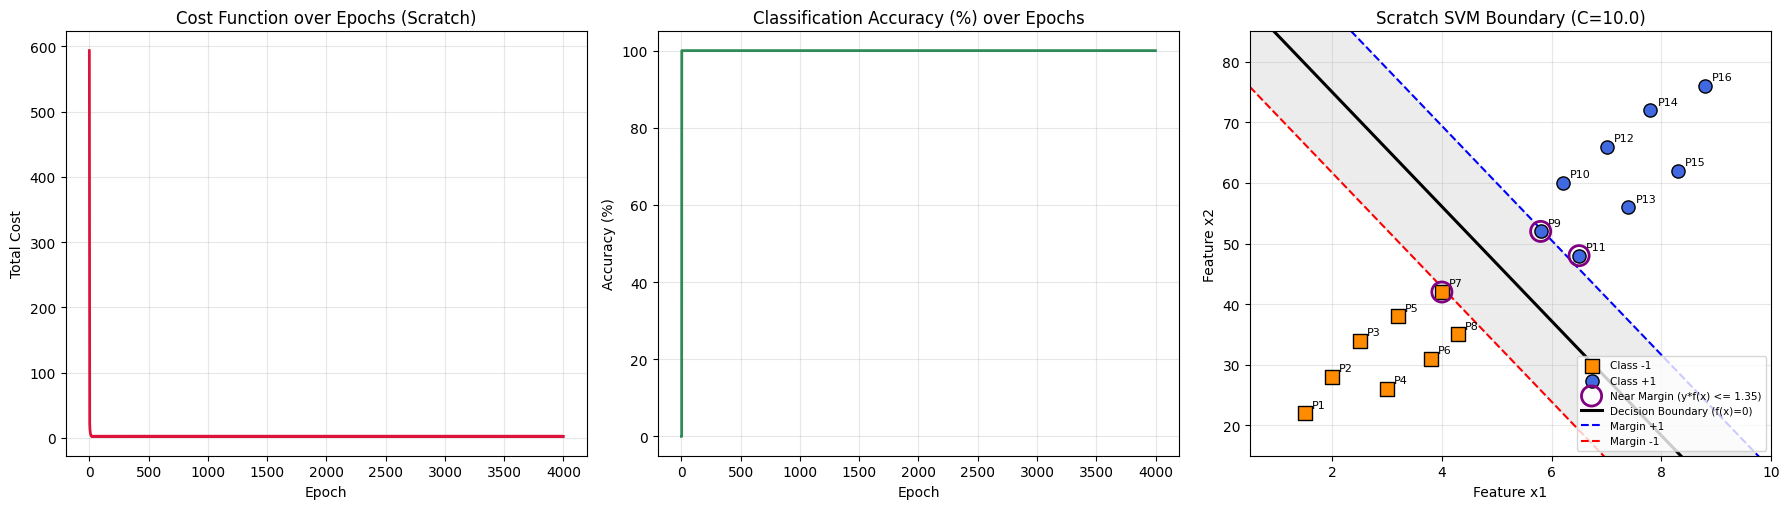

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# (ক) Cost Curve
axes[0].plot(hist["epoch"], hist["cost"], color="crimson", linewidth=2)
axes[0].set_title("Cost Function over Epochs (Scratch)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Cost")
axes[0].grid(True, alpha=0.3)

# (খ) Accuracy Curve
axes[1].plot(hist["epoch"], hist["accuracy"], color="seagreen", linewidth=2)
axes[1].set_title("Classification Accuracy (%) over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(-5, 105)
axes[1].grid(True, alpha=0.3)

# (গ) Decision Boundary ও Margin Lines
ax = axes[2]
ax.scatter(X[y == -1, 0], X[y == -1, 1], c="darkorange", marker="s", s=90, edgecolors="k", zorder=4, label="Class -1")
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="royalblue", marker="o", s=90, edgecolors="k", zorder=4, label="Class +1")

near_boundary_mask = (y * final_scores) <= 1.35
if np.any(near_boundary_mask):
    ax.scatter(
        X[near_boundary_mask, 0], X[near_boundary_mask, 1],
        s=210, facecolors="none", edgecolors="purple", linewidths=2, zorder=5,
        label="Near Margin (y*f(x) <= 1.35)"
    )

x1_grid = np.linspace(0.5, 10.0, 200)
if abs(w_opt[1]) > 1e-9:
    x2_dec = (-w_opt[0] * x1_grid - b_opt) / w_opt[1]
    x2_pos = (-w_opt[0] * x1_grid - b_opt + 1.0) / w_opt[1]
    x2_neg = (-w_opt[0] * x1_grid - b_opt - 1.0) / w_opt[1]

    ax.plot(x1_grid, x2_dec, "k-", linewidth=2.2, label="Decision Boundary (f(x)=0)")
    ax.plot(x1_grid, x2_pos, "b--", linewidth=1.5, label="Margin +1")
    ax.plot(x1_grid, x2_neg, "r--", linewidth=1.5, label="Margin -1")
    ax.fill_between(
        x1_grid, np.minimum(x2_pos, x2_neg), np.maximum(x2_pos, x2_neg),
        color="gray", alpha=0.15
    )

for i in range(len(y)):
    ax.annotate(f"P{i+1}", (X[i, 0], X[i, 1]), textcoords="offset points", xytext=(5, 4), fontsize=8)

ax.set_title(f"Scratch SVM Boundary (C={C_main})")
ax.set_xlabel("Feature x1")
ax.set_ylabel("Feature x2")
ax.set_xlim(0.5, 10.0)
ax.set_ylim(15.0, 85.0)
ax.legend(loc="lower right", fontsize=7.5)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 9 — Compare the Effect of Different C Values

এখন একই dataset ও training function ব্যবহার করে দুটি আলাদা `C` value তুলনা করা হচ্ছে:

- `C = 0.5`
- `C = 50.0`

প্রতিটি ক্ষেত্রে decision region, decision boundary এবং দুইটি margin line plot করা হচ্ছে।

সাধারণভাবে `C` hinge-loss violation-কে কতটা penalty দেবে তা নিয়ন্ত্রণ করে। তবে এখানে কোন `C`-তে margin কত হবে বা accuracy কত হবে, তা training result থেকেই দেখতে হবে; আগে থেকে নির্দিষ্ট ফল ধরে নেওয়া যাবে না।

**মনে রাখবে:** এই comparison-এ training logic পরিবর্তন করা হয়নি; শুধু `C`-এর মান পরিবর্তন করা হয়েছে।

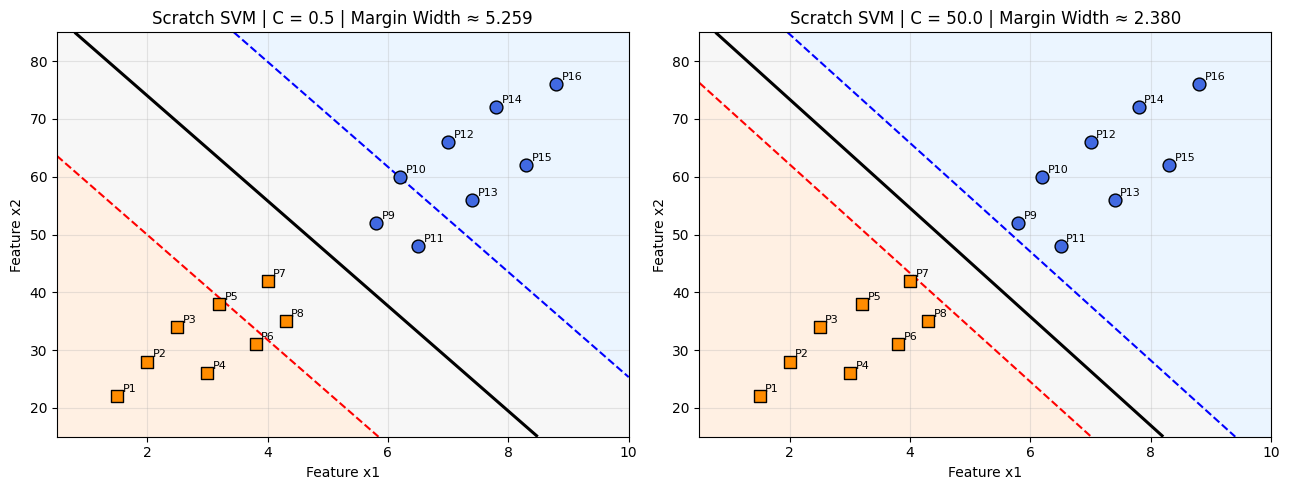

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, c_val in zip(axes, [0.5, 50.0]):
    ws_c, bs_c, _ = train_svm_scratch(
        X_scaled, y, C=c_val, lr=0.005, epochs=4000,
        w_init=w_bad_s, b_init=b_bad_s
    )
    wo_c, bo_c = convert_params_to_original_scale(ws_c, bs_c, mean_X, std_X)
    m_width = 2.0 / np.linalg.norm(wo_c)

    # Background region (f(x) >= 0 vs f(x) < 0)
    xx1, xx2 = np.meshgrid(
        np.linspace(0.5, 10.0, 200),
        np.linspace(15.0, 85.0, 200)
    )
    Z = wo_c[0] * xx1 + wo_c[1] * xx2 + bo_c

    ax.contourf(
        xx1, xx2, Z, levels=[-100, -1, 0, 1, 100],
        colors=["#ffe5cc", "#f2f2f2", "#f2f2f2", "#dceeff"],
        alpha=0.55
    )
    ax.contour(
        xx1, xx2, Z, levels=[-1, 0, 1],
        colors=["red", "black", "blue"],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.2, 1.5]
    )

    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="darkorange", marker="s", s=85, edgecolors="k", zorder=4)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="royalblue", marker="o", s=85, edgecolors="k", zorder=4)

    for i in range(len(y)):
        ax.annotate(f"P{i+1}", (X[i, 0], X[i, 1]), textcoords="offset points", xytext=(4, 3), fontsize=8)

    ax.set_title(f"Scratch SVM | C = {c_val} | Margin Width ≈ {m_width:.3f}")
    ax.set_xlabel("Feature x1")
    ax.set_ylabel("Feature x2")
    ax.set_xlim(0.5, 10.0)
    ax.set_ylim(15.0, 85.0)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 10 — How to Run and Read the Notebook

1. Notebook-এর প্রথম cell থেকে ক্রমানুসারে run করো।
2. কোনো cell error দিলে আগে তার আগের cell-গুলো run হয়েছে কি না দেখো।
3. Step 6-এ initial ভুল parameters-এর prediction দেখো।
4. Step 7-এ final `w`, `b`, accuracy এবং margin width দেখো।
5. Step 8-এ cost/accuracy curve এবং decision boundary বিশ্লেষণ করো।
6. Step 9-এ `C=0.5` ও `C=50`-এর boundary তুলনা করো।

**একটি গুরুত্বপূর্ণ ধারণা:** `y_i f(x_i) >= 1` হলে point-টি margin condition পূরণ করে। `y_i f(x_i) < 1` হলে সেটি margin condition ভঙ্গ করে এবং এই code-এ `viol` mask-এর মধ্যে পড়ে।